# 03 — Restoration-time regression

**Lights Out: Predicting Storm-Driven Power Outages and Recovery Across U.S. Counties**

Third step of our Option A analysis. The question: **once a storm has knocked out power in a county, how many hours
until 90% of the customers are back?** The target is `hours_to_90pct_restored`: hours from the outage peak until the
number of customers out stays at or below 10% of the peak for 6 hours (`data/DATA_DICTIONARY.md`).

Plan:

1. Build the modelling table and look at the target (long tail, so we model its logarithm).
2. Choose the features: the same storm-time features as `02_classifier.ipynb`, plus a second setup that also knows
   the size of the outage at its peak.
3. Evaluate with cross-validation **split by storm**, as in notebook 02, with regression metrics.
4. Start from very simple baselines, then compare five scikit-learn regressors.
5. Check two choices: the log target and the split by storm.
6. Tune the two best models a little, then test once on storms the models have never seen.
7. Look at what the model relies on and where it fails.
8. Discuss the rows we had to drop: the censored outages (`not_restored_in_window`).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit, KFold, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

DATA = Path('..') / 'data'
FIG = Path('..') / 'figures'
RES = Path('..') / 'results'
RES.mkdir(exist_ok=True)
SEED = 0
pd.set_option('display.max_columns', 40)
plt.rcParams['figure.figsize'] = (9, 4)

## 1. Modelling table and target

Same joins as in notebook 02: `utility_by_county.csv` (one row per storm and county) plus the storm type and date
from `storms.csv`, and the wind radius and pre-storm night light from `county_summary.csv`.

We keep the rows with `reason == 'ok'` (the utility reported something) **and** a known restoration time. The other
rows have an empty `hours_to_90pct_restored`, and `hours_to_90pct_reason` says why. We look at them in section 8.

In [2]:
storms = pd.read_csv(DATA / 'storms.csv')
utility = pd.read_csv(DATA / 'utility_by_county.csv', low_memory=False)
county = pd.read_csv(DATA / 'county_summary.csv', low_memory=False,
                     usecols=['event_id', 'geoid', 'in_nhc_wind_radius', 'baseline_radiance'])

storms['date'] = pd.to_datetime(storms['landfall'].fillna(storms['first_impact_date']), errors='coerce')
storms['year'] = storms['date'].dt.year
storms['month'] = storms['date'].dt.month

full = (utility.merge(storms[['event_id', 'name', 'kind', 'year', 'month']], on='event_id', how='left')
               .merge(county, on=['event_id', 'geoid'], how='left'))
full = full[full['reason'] == 'ok'].copy()
print('rows with utility data:', len(full))
print(full['hours_to_90pct_reason'].fillna('(known value)').value_counts().to_string())

df = full[full['hours_to_90pct_restored'].notna()].copy()
print(f"\nusable rows: {len(df):,} from {df['event_id'].nunique()} storms")

rows with utility data: 10260
hours_to_90pct_reason
(known value)             7297
reporting_drop            1752
not_restored_in_window    1165
no_customers_out            45
peak_mismatch                1

usable rows: 7,297 from 449 storms


The target has a very long right tail: half of the counties are back within about 30 hours, a few take more than
40 days. A model trained on raw hours would spend most of its effort on those few extreme counties, and an error
of 10 hours does not mean the same thing for a 3-hour outage and for a 300-hour one.

So we model **`log(1 + hours)`**. On the log scale the distribution is much closer to symmetric, and an error on the
log scale is a *relative* error: an absolute error of 0.69 on the log scale means "off by a factor of 2".

count    7297.0
mean       63.1
std       101.0
min         0.5
25%        11.0
50%        30.2
75%        72.0
max      1009.5


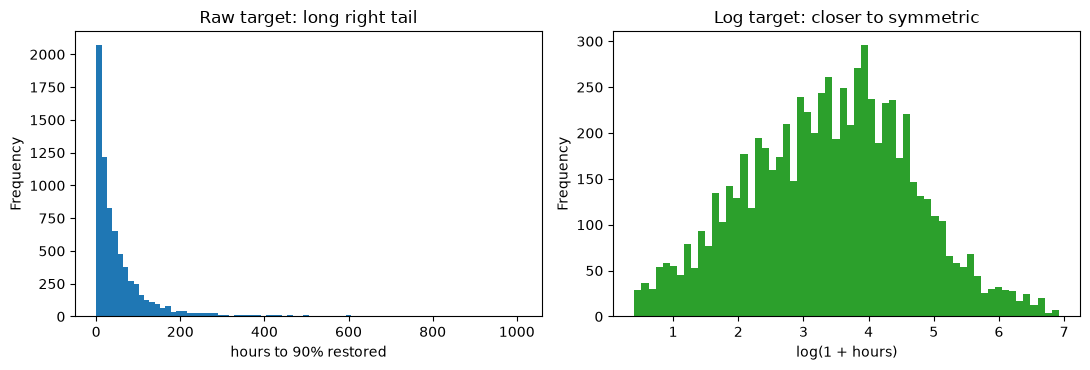

In [3]:
df['log_hours'] = np.log1p(df['hours_to_90pct_restored'])
print(df['hours_to_90pct_restored'].describe().round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
df['hours_to_90pct_restored'].plot.hist(bins=80, ax=axes[0], color='tab:blue')
axes[0].set_xlabel('hours to 90% restored'); axes[0].set_title('Raw target: long right tail')
df['log_hours'].plot.hist(bins=60, ax=axes[1], color='tab:green')
axes[1].set_xlabel('log(1 + hours)'); axes[1].set_title('Log target: closer to symmetric')
plt.tight_layout(); plt.show()

## 2. Features

We compare two setups. Both use only information that exists **when the restoration starts** (the target is counted
from the peak):

| Setup | Features | Use case |
|---|---|---|
| **A. Storm time** | `kind`, `state`, `wind_radius`, `year`, `month`, `log_customers`, `log_baseline` (the features of notebook 02) | Before the storm hits: plan crews and warnings |
| **B. At the peak** | A + `log_peak` = log(1 + `peak_customers_out`) and `peak_share_out` | When the utility has reported how many customers are out |

Setup B is not leakage here: the clock of the target starts at the peak, so the size of the peak is known when we
want the prediction. What we leave out is everything measured *during* the restoration: `customer_hours_out`,
`hours_to_50pct_restored` and `hours_under_1pct_customers` all contain part of the answer.

`customers_total` (so `log_customers`) and `peak_share_out` are empty for 244 rows: the county has no customer
estimate, or more customers were reported out than the estimate. Gradient boosting handles missing values natively;
the other pipelines fill them with the median of the training folds.

In [4]:
df['log_customers'] = np.log1p(df['customers_total'])
df['log_baseline'] = np.log1p(df['baseline_radiance'])
df['log_peak'] = np.log1p(df['peak_customers_out'])
df['wind_radius'] = (df['in_nhc_wind_radius'].astype('string').str.lower()
                       .map({'true': 'inside', 'false': 'outside'}).fillna('unknown'))

CAT = ['kind', 'state', 'wind_radius']
NUM_A = ['year', 'month', 'log_customers', 'log_baseline']
NUM_B = NUM_A + ['log_peak', 'peak_share_out']

X = df[CAT + NUM_B]
y = df['log_hours'].to_numpy()
groups = df['event_id'].to_numpy()

print('missing values per feature:')
print(X.isna().sum().to_string())

missing values per feature:
kind                0
state               0
wind_radius         0
year                0
month               0
log_customers     244
log_baseline        0
log_peak            0
peak_share_out    244


## 3. How to evaluate: split by storm, regression metrics

As in notebook 02, counties of the same storm share the weather, the date and often the utility, so a storm must be
either fully in training or fully in testing (`GroupKFold`, group = `event_id`). We again keep 20% of the storms aside
as a **final test set**, used once in section 6.

Metrics, all computed on the log target:

- **MAE (log)**: mean absolute error on the log scale. We also show it as a **typical error factor**
  `exp(MAE)`: 2.0 means a typical prediction is off by a factor of 2 (for example 15 h instead of 30 h, or 60 h).
- **R²**: share of the variance explained. 0 = no better than always predicting the mean, 1 = perfect.

In section 6 we also translate the errors back into hours.

In [5]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
g_train = groups[train_idx]

print(f'train: {len(train_idx):,} rows, {len(set(g_train))} storms, median {np.expm1(np.median(y_train)):.1f} h')
print(f'test : {len(test_idx):,} rows, {len(set(groups[test_idx]))} storms, median {np.expm1(np.median(y_test)):.1f} h')
print('storms in both sets:', len(set(g_train) & set(groups[test_idx])))

cv = GroupKFold(n_splits=5)
SCORING = {'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

train: 6,034 rows, 359 storms, median 30.8 h
test : 1,263 rows, 90 storms, median 28.8 h
storms in both sets: 0


## 4. Simple baselines

1. **Constant**: always predict the mean log time of the training folds. R² is about 0 by definition.
2. **Storm-type lookup table**: predict the mean log time seen for that storm type in the training folds.
3. **Peak-size lookup table** (uses setup B information): split the training counties into 10 groups by the size of
   the peak and predict the mean of the group. It tells us whether a bigger outage simply takes longer.

In [6]:
def lookup_scores(key_fn, X_, y_, g_):
    mae, r2 = [], []
    for tr, te in cv.split(X_, y_, g_):
        k_tr, k_te = key_fn(X_.iloc[tr], X_.iloc[tr]), key_fn(X_.iloc[te], X_.iloc[tr])
        table = pd.Series(y_[tr]).groupby(k_tr.to_numpy()).mean()
        pred = pd.Series(k_te.to_numpy()).map(table).fillna(y_[tr].mean()).to_numpy()
        mae.append(mean_absolute_error(y_[te], pred)); r2.append(r2_score(y_[te], pred))
    return {'mae': np.array(mae), 'r2': np.array(r2)}

def constant(X_te, X_tr):
    return pd.Series(0, index=X_te.index)

def by_kind(X_te, X_tr):
    return X_te['kind']

def by_peak_decile(X_te, X_tr):
    edges = np.unique(np.quantile(X_tr['log_peak'], np.linspace(0, 1, 11)))
    return pd.Series(np.digitize(X_te['log_peak'], edges[1:-1]), index=X_te.index)

baselines = {
    'Constant (mean)': lookup_scores(constant, X_train, y_train, g_train),
    'Storm-type lookup table': lookup_scores(by_kind, X_train, y_train, g_train),
    'Peak-size lookup table (B)': lookup_scores(by_peak_decile, X_train, y_train, g_train),
}
for name, s in baselines.items():
    print(f"{name:28s} MAE {s['mae'].mean():.3f} (x{np.exp(s['mae'].mean()):.2f})   R2 {s['r2'].mean():+.3f}")

Constant (mean)              MAE 1.024 (x2.79)   R2 -0.012
Storm-type lookup table      MAE 1.016 (x2.76)   R2 -0.008
Peak-size lookup table (B)   MAE 0.965 (x2.62)   R2 +0.078


## 5. Comparing five models

Five classic scikit-learn regressors, the regression versions of the classifiers of notebook 02 (Naive Bayes has no
regression version, so k-nearest neighbours takes its place):

| Model | Why we try it |
|---|---|
| Linear regression (ridge) | Linear baseline promised in our proposal; a small L2 penalty keeps the 50 state dummies stable |
| k-nearest neighbours (k = 25) | Predicts the mean of the 25 most similar counties, no training at all |
| Decision tree (depth 6) | Can be drawn and explained |
| Random forest | Many trees on random subsets, robust with little tuning |
| Gradient boosting (`HistGradientBoostingRegressor`) | Usually the best choice for tables |

Same preprocessing as in notebook 02: one-hot encoding and scaling inside a `Pipeline` for the first four, ordinal
encoding with native categories for gradient boosting. Each model is run with both feature setups.

In [7]:
def onehot(model, num, scale=True):
    num_pipe = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()) if scale else SimpleImputer(strategy='median')
    pre = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False), CAT),
        ('num', num_pipe, num)])
    return make_pipeline(pre, model)

def ordinal(model, num):
    pre = ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1, encoded_missing_value=-1), CAT),
        ('num', 'passthrough', num)])
    return make_pipeline(pre, model)

def make_models(num):
    return {
        'Linear regression (ridge)': onehot(Ridge(alpha=1.0), num),
        'k-nearest neighbours': onehot(KNeighborsRegressor(n_neighbors=25), num),
        'Decision tree (depth 6)': onehot(DecisionTreeRegressor(max_depth=6, min_samples_leaf=20, random_state=SEED), num, scale=False),
        'Random forest': onehot(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=0.5,
                                                      n_jobs=-1, random_state=SEED), num, scale=False),
        'Gradient boosting': ordinal(HistGradientBoostingRegressor(categorical_features=[0, 1, 2], random_state=SEED), num),
    }

SETUPS = {'A': NUM_A, 'B': NUM_B}
rows = []
for name, s in baselines.items():
    rows.append({'model': name, 'setup': 'baseline', 'MAE (log)': s['mae'].mean(), 'R2': s['r2'].mean(), 'R2 std': s['r2'].std()})
for setup, num in SETUPS.items():
    for name, model in make_models(num).items():
        s = cross_validate(model, X_train[CAT + num], y_train, groups=g_train, cv=cv, scoring=SCORING, n_jobs=-1)
        rows.append({'model': name, 'setup': setup, 'MAE (log)': -s['test_mae'].mean(),
                     'R2': s['test_r2'].mean(), 'R2 std': s['test_r2'].std()})

table = pd.DataFrame(rows)
table['error factor'] = np.exp(table['MAE (log)'])
table.sort_values(['setup', 'R2']).round(3)

,model,setup,MAE (log),R2,R2 std,error factor
4,k-nearest neighbours,A,1.019,-0.023,0.015,2.770
7,Gradient boosting,A,1.003,0.003,0.041,2.727
5,Decision tree (depth 6),A,1.003,0.008,0.055,2.726
6,Random forest,A,0.992,0.028,0.047,2.695
3,Linear regression (ridge),A,0.997,0.028,0.024,2.711
8,Linear regression (ridge),B,0.947,0.084,0.032,2.579
9,k-nearest neighbours,B,0.896,0.175,0.030,2.450
12,Gradient boosting,B,0.873,0.186,0.057,2.395
10,Decision tree (depth 6),B,0.874,0.189,0.073,2.396
11,Random forest,B,0.857,0.218,0.058,2.356


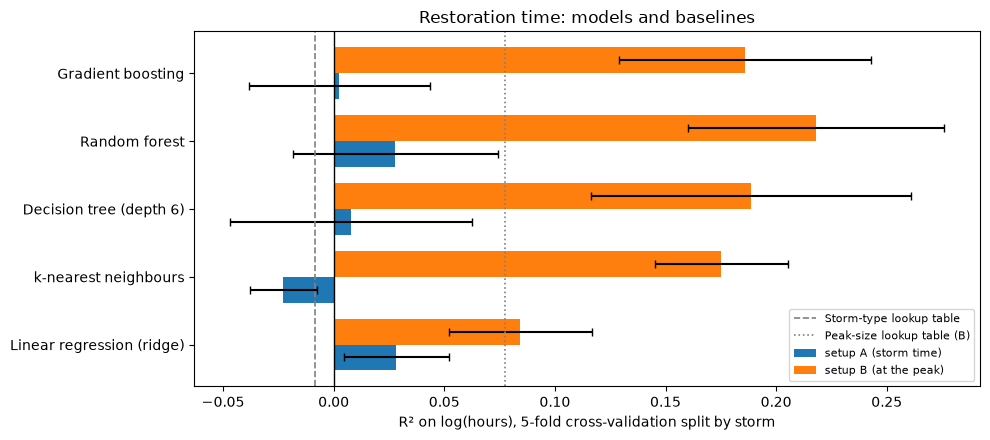

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
models_order = list(make_models(NUM_A))
pos = np.arange(len(models_order))
for k, (setup, color) in enumerate([('A', 'tab:blue'), ('B', 'tab:orange')]):
    t = table[table['setup'] == setup].set_index('model').loc[models_order]
    ax.barh(pos + (k - 0.5) * 0.38, t['R2'], height=0.38, xerr=t['R2 std'], color=color, capsize=3,
            label=f'setup {setup}' + (' (storm time)' if setup == 'A' else ' (at the peak)'))
for name, ls in [('Storm-type lookup table', '--'), ('Peak-size lookup table (B)', ':')]:
    ax.axvline(table.set_index('model').loc[name, 'R2'], color='gray', ls=ls, lw=1.2, label=name)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(pos, models_order)
ax.set_xlabel('R² on log(hours), 5-fold cross-validation split by storm')
ax.set_title('Restoration time: models and baselines')
ax.legend(loc='lower right', fontsize=8)
plt.tight_layout()
fig.savefig(FIG / 'regression_models.png', dpi=150, bbox_inches='tight')
plt.show()

This is the main result of the notebook, and it is very different from notebook 02:

- **With setup A (storm-time features only), no model really beats the constant.** The best R² is about 0.03: storm
  type, state, date and county size say almost nothing about how long the restoration will take. The same features
  gave an AUC of 0.72 for *whether* a major outage happens. They tell us *if* a county loses power, not *how long* it
  stays dark.
- **Knowing the size of the outage helps a lot.** The peak-size lookup table alone (10 groups, no model) already
  beats every setup A model. With setup B, the tree ensembles reach an R² of about 0.2 and the typical error factor
  drops from 2.8 to 2.4.
- The linear model gains much less from setup B than the trees: the effect of the peak size is not a straight line
  on these scales, and trees capture it more easily.
- Even the best model leaves about 80% of the variance unexplained. The restoration time depends on things we do not
  have: wind speed, how much of the network is physically destroyed, crews available, access roads, flooding.

## 5b. Two choices to check

### Does the log target help?

Same random forest (setup B), trained once on raw hours and once on log hours (`TransformedTargetRegressor` takes
the log before fitting and converts predictions back to hours). Both are scored **in hours**: mean absolute error
and median absolute error.

In [9]:
y_hours_train = np.expm1(y_train)
rf_b = make_models(NUM_B)['Random forest']
candidates = {
    'raw hours': rf_b,
    'log hours': TransformedTargetRegressor(regressor=rf_b, func=np.log1p, inverse_func=np.expm1),
}
log_check = {}
for name, model in candidates.items():
    s = cross_validate(model, X_train[CAT + NUM_B], y_hours_train, groups=g_train, cv=cv, n_jobs=-1,
                       scoring={'mae': 'neg_mean_absolute_error', 'medae': 'neg_median_absolute_error'})
    log_check[name] = {'mean abs. error (h)': -s['test_mae'].mean(), 'median abs. error (h)': -s['test_medae'].mean()}
    print(f"trained on {name:9s}: mean abs. error {-s['test_mae'].mean():5.1f} h, median abs. error {-s['test_medae'].mean():5.1f} h")

trained on raw hours: mean abs. error  50.5 h, median abs. error  27.7 h


trained on log hours: mean abs. error  44.7 h, median abs. error  17.9 h


Training on the log target gives a better model **in hours** too: the median error goes from about 28 h to 18 h
and the mean error from about 50 h to 45 h. Trained on raw hours, the forest is pulled up by the few 500 to 1,000-hour
restorations and over-predicts the many short ones.

### Why the split matters

Same gradient boosting model (setup B), folds cut by storm or at random.

In [10]:
gb_b = make_models(NUM_B)['Gradient boosting']
split_check = {}
for name, split, g in [('split by storm', cv, g_train), ('random split', KFold(5, shuffle=True, random_state=SEED), None)]:
    s = cross_validate(gb_b, X_train[CAT + NUM_B], y_train, groups=g, cv=split, scoring=SCORING, n_jobs=-1)
    split_check[name] = {'R2': s['test_r2'].mean(), 'MAE (log)': -s['test_mae'].mean()}
    print(f"{name:15s}: R2 {s['test_r2'].mean():.3f}, MAE (log) {-s['test_mae'].mean():.3f}")

split by storm : R2 0.186, MAE (log) 0.873


random split   : R2 0.250, MAE (log) 0.824


As in notebook 02, a random split looks better (R² 0.25 instead of 0.19), because counties of the same storm restore at
similar speeds and the model has already seen some of them. We keep the split by storm.

## 6. A little tuning, then the final test

We tune the two tree ensembles with small grids, for each setup, still with the split by storm on the training storms
only. For each setup we keep the model with the best cross-validated R² and evaluate it **once** on the test storms.

In [11]:
def searches_for(num):
    return {
        'Random forest': GridSearchCV(
            onehot(RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=SEED), num, scale=False),
            {'randomforestregressor__min_samples_leaf': [5, 20, 50],
             'randomforestregressor__max_features': ['sqrt', 0.5]},
            cv=cv, scoring='r2', n_jobs=-1),
        'Gradient boosting': GridSearchCV(
            ordinal(HistGradientBoostingRegressor(categorical_features=[0, 1, 2], random_state=SEED), num),
            {'histgradientboostingregressor__learning_rate': [0.03, 0.1],
             'histgradientboostingregressor__max_leaf_nodes': [15, 31],
             'histgradientboostingregressor__l2_regularization': [0.0, 1.0]},
            cv=cv, scoring='r2', n_jobs=-1),
    }

final = {}
for setup, num in SETUPS.items():
    searches = searches_for(num)
    for name, search in searches.items():
        search.fit(X_train[CAT + num], y_train, groups=g_train)
        short = {k.split('__')[1]: v for k, v in search.best_params_.items()}
        print(f'setup {setup}  {name:18s} best CV R2 {search.best_score_:.3f} with {short}')
    best_name = max(searches, key=lambda k: searches[k].best_score_)
    final[setup] = (best_name, searches[best_name].best_estimator_, num)

setup A  Random forest      best CV R2 0.054 with {'max_features': 'sqrt', 'min_samples_leaf': 20}


setup A  Gradient boosting  best CV R2 0.042 with {'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15}


setup B  Random forest      best CV R2 0.227 with {'max_features': 0.5, 'min_samples_leaf': 50}


setup B  Gradient boosting  best CV R2 0.229 with {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_leaf_nodes': 15}


In [12]:
def report(y_true_log, pred_log):
    h_true, h_pred = np.expm1(y_true_log), np.expm1(pred_log)
    mae = mean_absolute_error(y_true_log, pred_log)
    return {'R2 (log)': r2_score(y_true_log, pred_log), 'MAE (log)': mae, 'error factor': np.exp(mae),
            'median abs. error (h)': median_absolute_error(h_true, h_pred),
            'mean abs. error (h)': mean_absolute_error(h_true, h_pred)}

const_pred = np.full_like(y_test, y_train.mean())
results = {'Constant (training mean)': report(y_test, const_pred)}
test_pred = {}
for setup, (name, model, num) in final.items():
    test_pred[setup] = model.predict(X_test[CAT + num])
    results[f'{setup}: {name}'] = report(y_test, test_pred[setup])
pd.DataFrame(results).T.round(3)

,R2 (log),MAE (log),error factor,median abs. error (h),mean abs. error (h)
Constant (training mean),-0.002,1.024,2.786,21.967,50.086
A: Random forest,0.047,1.007,2.738,19.789,49.663
B: Gradient boosting,0.208,0.884,2.421,16.185,45.183


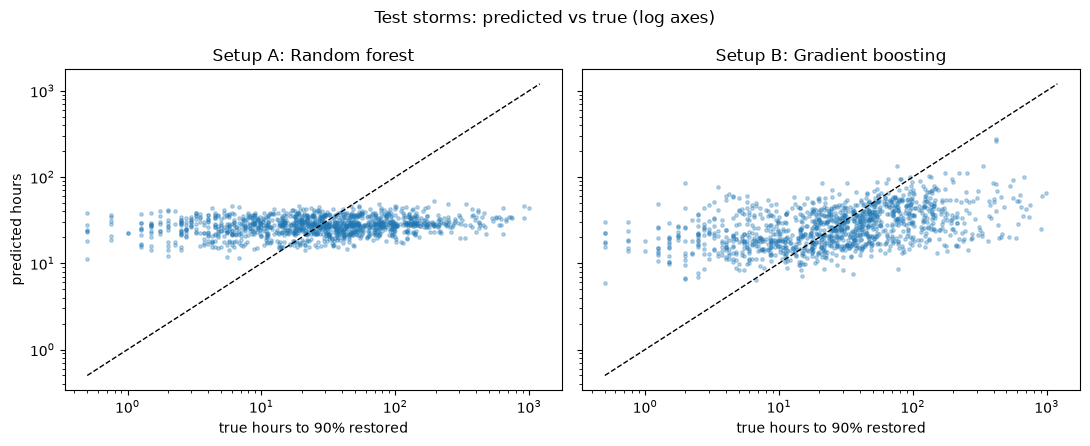

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
h_true = np.expm1(y_test)
for ax, setup in zip(axes, final):
    ax.scatter(h_true, np.expm1(test_pred[setup]), s=6, alpha=0.3)
    ax.plot([0.5, 1200], [0.5, 1200], 'k--', lw=1)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('true hours to 90% restored')
    ax.set_title(f'Setup {setup}: {final[setup][0]}')
axes[0].set_ylabel('predicted hours')
plt.suptitle('Test storms: predicted vs true (log axes)')
plt.tight_layout()
fig.savefig(FIG / 'regression_test.png', dpi=150, bbox_inches='tight')
plt.show()

On the 90 storms kept aside since section 3, the results match the cross-validation:

- **Setup A**: R² about 0.05, almost no better than predicting the mean for everybody.
- **Setup B**: R² about 0.21, typical error factor 2.4, median error about 16 hours instead of 22 hours for the
  constant.

The scatter plots show the problem clearly. Setup A predicts nearly the same 20 to 40 hours for every county. Setup B
spreads its predictions more, but it is still too cautious: short outages are over-predicted and long ones
under-predicted (the cloud is flatter than the diagonal). This is typical of a model that only explains a small
share of the variance: when it is unsure, it stays close to the average.

## 7. What the model relies on, and where it fails

**Permutation importance** on the test storms (setup B model): shuffle one feature and measure how much R² drops.

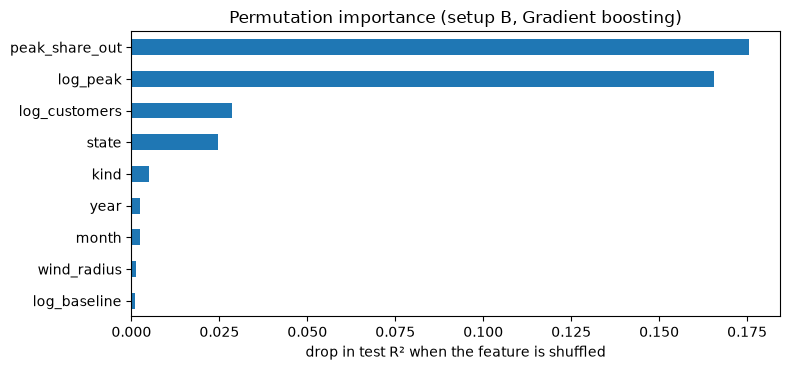

peak_share_out    0.176
log_peak          0.165
log_customers     0.029
state             0.025
kind              0.005
year              0.003
month             0.002
wind_radius       0.001
log_baseline      0.001
dtype: float64

In [14]:
name_b, model_b, num_b = final['B']
imp = permutation_importance(model_b, X_test[CAT + num_b], y_test, scoring='r2', n_repeats=10,
                             random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=CAT + num_b).sort_values()
ax = imp.plot.barh(figsize=(8, 3.8))
ax.set_xlabel('drop in test R² when the feature is shuffled')
ax.set_title(f'Permutation importance (setup B, {name_b})')
plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3)

Errors per storm type and per storm. A positive residual means the restoration took **longer** than predicted.

In [15]:
test_df = df.iloc[test_idx].assign(pred=test_pred['B'], resid=lambda d: d['log_hours'] - d['pred'])
err_by_kind = (test_df.groupby('kind')
                      .agg(rows=('resid', 'size'), storms=('event_id', 'nunique'),
                           mean_resid=('resid', 'mean'), mae_log=('resid', lambda r: r.abs().mean()))
                      .sort_values('rows', ascending=False))
err_by_kind['error factor'] = np.exp(err_by_kind['mae_log'])
display(err_by_kind.round(2))

by_storm = (test_df.groupby(['event_id', 'name'])
                   .agg(rows=('resid', 'size'), median_true_h=('hours_to_90pct_restored', 'median'),
                        median_pred_h=('pred', lambda p: np.expm1(p).median()), mean_resid=('resid', 'mean'))
                   .query('rows >= 20').sort_values('mean_resid'))
print('Test storms with at least 20 counties, worst under- and over-estimates:')
pd.concat([by_storm.head(3), by_storm.tail(3)]).round(2)

,rows,storms,mean_resid,mae_log,error factor
kind,,,,,
severe_storm,589,50,0.08,0.89,2.43
tropical,356,7,0.04,0.73,2.08
flood,262,26,-0.12,1.08,2.93
winter_storm,18,2,0.52,0.77,2.16
snowstorm,16,2,0.19,0.95,2.59
straight-line_winds,10,1,0.15,0.89,2.43
severe_ice_storm,8,1,0.89,0.98,2.66
tornado,4,1,1.37,1.37,3.92


Test storms with at least 20 counties, worst under- and over-estimates:


,,rows,median_true_h,median_pred_h,mean_resid
event_id,name,,,,
DR-4318,"Severe Storms, Tornadoes, Straight-Line Winds, And Flooding",24,17.50,28.05,-0.39
DR-4449,"Severe Storms, Straight-Line Winds, Tornadoes, Flooding,Landslides,And Mudslides",41,10.25,19.69,-0.35
AL082021,Henri,38,11.62,15.35,-0.33
AL092017,Harvey,45,25.25,18.46,0.28
DR-4238,"Severe Storms, Tornadoes, Straight-Line Winds, And Flooding",25,21.75,21.45,0.42
DR-4557,Severe Storms,23,124.25,31.51,1.29


The same errors as a picture. For each test county, the ratio between the true and the predicted time (`(1 + true) / (1 + predicted)`, log scale): 1 is a perfect prediction, 2 means the restoration took twice as long as predicted, 0.5 half as long. Only storm types with at least 10 test counties are shown.

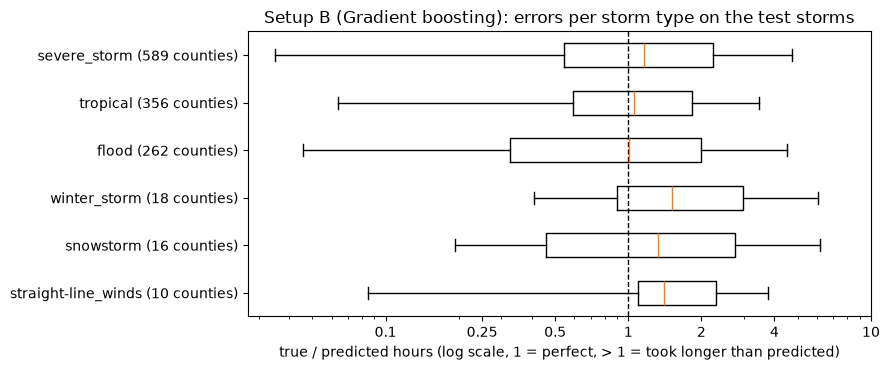

In [16]:
kinds = err_by_kind[err_by_kind['rows'] >= 10].index.tolist()[::-1]
ratios = [np.exp(test_df.loc[test_df['kind'] == k, 'resid']) for k in kinds]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot(ratios, orientation='horizontal', showfliers=False)
ax.set_yticks(range(1, len(kinds) + 1), [f"{k} ({err_by_kind.loc[k, 'rows']} counties)" for k in kinds])
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.set_xticks([0.1, 0.25, 0.5, 1, 2, 4, 10], ['0.1', '0.25', '0.5', '1', '2', '4', '10'])
ax.set_xlabel('true / predicted hours (log scale, 1 = perfect, > 1 = took longer than predicted)')
ax.set_title(f'Setup B ({name_b}): errors per storm type on the test storms')
plt.tight_layout()
fig.savefig(FIG / 'regression_errors_by_kind.png', dpi=150, bbox_inches='tight')
plt.show()

- The model mostly uses the **size of the outage**: share of customers out at the peak, then number of customers out.
  Storm type, date, wind radius and night light add almost nothing once the peak is known.
- **Tropical storms** are predicted best (error factor about 2.1). Their counties are many and similar.
- **Floods** are predicted worst (error factor about 2.9), and they are also the most censored type (section 8).
- Ice storms, winter storms and tornadoes are under-predicted (positive mean residual), but the test set has very few
  of them, so these numbers are fragile.
- The errors are strongly shared by all the counties of a storm: for DR-4557 the median county took 124 hours and
  the model predicted about 32 hours. Something specific to that storm (damage, crews, terrain) is missing from our
  features. Wind data from HURDAT2 could fix part of this for Atlantic storms.

## 8. The rows we dropped: censoring

We trained only on counties with a known restoration time. Two groups of rows with utility data were left out:

- `reporting_drop`: the utility feed stopped partway through. The restoration time is simply **unknown**; there is no
  reason to think these outages are longer or shorter, so dropping them mostly costs data.
- `not_restored_in_window`: still above 10% of the peak when the 45-day observation window ends. Here we know
  something: the true time is **longer than what we observed**. This is called **right-censoring**. Dropping these
  rows removes the longest restorations, so the model learns that restorations are shorter than they really are.

Which counties are censored?

In [17]:
full['group'] = full['hours_to_90pct_reason'].fillna('known')
comp = (full[full['group'].isin(['known', 'not_restored_in_window', 'reporting_drop'])]
        .groupby('group')
        .agg(rows=('geoid', 'size'), median_peak_customers=('peak_customers_out', 'median'),
             median_peak_share=('peak_share_out', 'median'), median_customers=('customers_total', 'median')))
display(comp.round(3))

cens_rate = (full.groupby('kind')['hours_to_90pct_reason']
                 .agg(rows='size', censored=lambda r: (r == 'not_restored_in_window').mean())
                 .sort_values('censored', ascending=False))
cens_rate.round(3)

,rows,median_peak_customers,median_peak_share,median_customers
group,,,,
known,7297,2733.0,0.138,17481.3
not_restored_in_window,1165,153.0,0.019,7117.7
reporting_drop,1752,1128.5,0.060,16823.1


,rows,censored
kind,,
flood,1780,0.215
snowstorm,219,0.196
severe_storm,3348,0.136
straight-line_winds,39,0.128
winter_storm,124,0.113
tornado,190,0.089
severe_ice_storm,620,0.068
tropical,3935,0.052
coastal_storm,5,0.000


This corrects what we expected after the exploration. In `01_eda.ipynb` we assumed the censored rows were the
**biggest** outages. They are not: the median censored county had only about **150 customers out at the peak**
(2% of the county), against about 2,700 (14%) for the counties we kept. A typical censored case is a small outage
where a handful of customers stay out for weeks: 10% of a 150-customer peak is 15 customers, and a few destroyed or
unreachable homes are enough to stay above that line.

Floods and snowstorms are censored at the highest rate (about 20% of their rows) and tropical storms at the lowest (5%).
In absolute numbers, severe storms have the most censored rows, because they have many more rows overall. So by
dropping the censored rows, we under-estimate restoration times most, in relative terms, for floods.

**Does our model see these counties as long restorations?** We predict the censored counties of the test storms with
the setup B model. A model that had learned the right pattern should give them long times (their true time is at
least several days, since the window lasts 45 days from the impact).

In [18]:
test_storms = set(groups[test_idx])
cens = full[(full['hours_to_90pct_reason'] == 'not_restored_in_window') & full['event_id'].isin(test_storms)].copy()
cens['log_customers'] = np.log1p(cens['customers_total'])
cens['log_baseline'] = np.log1p(cens['baseline_radiance'])
cens['log_peak'] = np.log1p(cens['peak_customers_out'])
cens['wind_radius'] = (cens['in_nhc_wind_radius'].astype('string').str.lower()
                         .map({'true': 'inside', 'false': 'outside'}).fillna('unknown'))
cens_pred = np.expm1(model_b.predict(cens[CAT + num_b]))
known_pred = np.expm1(test_pred['B'])
print(f'censored test counties: {len(cens)}')
print(f'median prediction, censored counties : {np.median(cens_pred):6.1f} h')
print(f'median prediction, known counties    : {np.median(known_pred):6.1f} h')
print(f'censored counties predicted above 1 week: {(cens_pred > 168).mean():.1%}')

censored test counties: 203
median prediction, censored counties :   50.3 h
median prediction, known counties    :   25.3 h
censored counties predicted above 1 week: 2.0%


**Sensitivity check.** A simple way to keep the censored rows is to give them a value instead of dropping them. We
know their true time is long, but not how long, so we try the longest restoration time observed in the training
counties (about 1,000 hours, roughly the length of the window) as a rough stand-in. If the conclusions changed a lot,
the censoring would be a serious problem for our results.

In [19]:
train_storms = set(g_train)
cens_train = full[(full['hours_to_90pct_reason'] == 'not_restored_in_window') & full['event_id'].isin(train_storms)].copy()
for c, src in [('log_customers', 'customers_total'), ('log_baseline', 'baseline_radiance'), ('log_peak', 'peak_customers_out')]:
    cens_train[c] = np.log1p(cens_train[src])
cens_train['wind_radius'] = (cens_train['in_nhc_wind_radius'].astype('string').str.lower()
                               .map({'true': 'inside', 'false': 'outside'}).fillna('unknown'))
cap = y_train.max()
X_aug = pd.concat([X_train[CAT + num_b], cens_train[CAT + num_b]])
y_aug = np.concatenate([y_train, np.full(len(cens_train), cap)])

from sklearn.base import clone
model_aug = clone(model_b).fit(X_aug, y_aug)
pred_aug = model_aug.predict(X_test[CAT + num_b])
print(f'censored training rows added: {len(cens_train)}, all set to {np.expm1(cap):.0f} h')
print(f"test R2 on known counties, censored rows dropped : {r2_score(y_test, test_pred['B']):.3f}")
print(f'test R2 on known counties, censored rows filled  : {r2_score(y_test, pred_aug):.3f}')
print(f'median prediction on censored test counties, dropped -> filled: '
      f'{np.median(cens_pred):.1f} h -> {np.median(np.expm1(model_aug.predict(cens[CAT + num_b]))):.1f} h')

censored training rows added: 935, all set to 1010 h
test R2 on known counties, censored rows dropped : 0.208
test R2 on known counties, censored rows filled  : 0.122
median prediction on censored test counties, dropped -> filled: 50.3 h -> 212.4 h


- The model trained without censored rows **already ranks them as longer** than the others (median prediction about
  50 h against 25 h), but it predicts more than a week for only 2% of them. It cannot predict times it has never seen.
- Filling the censored rows with about 1,000 hours pushes their predictions up (median about 210 h), but **lowers
  the R² on the known counties** from 0.21 to 0.12. The stand-in value is too crude: these small outages are pulled
  to the far end of the scale, and the model generalises this to normal small outages.

Neither option is fully right. The proper tool is **survival analysis**, which uses a censored row as "at least
this long" instead of an exact value: Cox models, accelerated failure time models or random survival forests
(libraries `lifelines` or `scikit-survival`). It needs the time between the peak and the end of the window for each
censored county, which this dataset does not give directly (only the window length from the impact date). We leave it
as an extension and report our model as a model of **restorations completed within the 45-day window**.

## 9. Summary and next steps

Save the numbers and the test predictions in `results/`, so that the report tables can be checked and `04_report_figures.ipynb` can redraw the figures without retraining.

In [20]:
import json

table.to_csv(RES / 'regression_cv_summary.csv', index=False)
pd.DataFrame(results).T.rename_axis('model').to_csv(RES / 'regression_test_metrics.csv')
(df.iloc[test_idx][['event_id', 'name', 'kind', 'state', 'year', 'geoid', 'hours_to_90pct_restored', 'log_hours']]
   .assign(pred_log_A=test_pred['A'], pred_log_B=test_pred['B'],
           pred_hours_A=np.expm1(test_pred['A']), pred_hours_B=np.expm1(test_pred['B']))
   .to_csv(RES / 'regression_test_predictions.csv', index=False))
err_by_kind.to_csv(RES / 'regression_errors_by_kind.csv')
by_storm.reset_index().to_csv(RES / 'regression_errors_by_storm.csv', index=False)
imp.sort_values(ascending=False).rename('drop in test R2').rename_axis('feature').to_csv(RES / 'regression_importance.csv')
comp.to_csv(RES / 'regression_censored_profile.csv')
cens_rate.to_csv(RES / 'regression_censored_by_kind.csv')
(RES / 'regression_summary.json').write_text(json.dumps({
    'final_models': {s: {'model': n, **{k: v for k, v in m[-1].get_params().items()
                                        if k in ('min_samples_leaf', 'max_features', 'learning_rate',
                                                 'max_leaf_nodes', 'l2_regularization')}}
                     for s, (n, m, _) in final.items()},
    'log_check_cv_hours': log_check,
    'split_check_cv': split_check,
    'censored_test': {'rows': int(len(cens)), 'median_pred_hours': float(np.median(cens_pred)),
                      'median_pred_hours_known': float(np.median(known_pred)),
                      'share_pred_above_1_week': float((cens_pred > 168).mean())},
    'censored_filled': {'train_rows_added': int(len(cens_train)), 'fill_hours': float(np.expm1(cap)),
                        'test_r2_dropped': float(r2_score(y_test, test_pred['B'])),
                        'test_r2_filled': float(r2_score(y_test, pred_aug)),
                        'median_pred_censored_filled': float(np.median(np.expm1(model_aug.predict(cens[CAT + num_b]))))},
}, indent=1, default=float))
sorted(f.name for f in RES.glob('regression_*'))

['regression_censored_by_kind.csv',
 'regression_censored_profile.csv',
 'regression_cv_summary.csv',
 'regression_errors_by_kind.csv',
 'regression_errors_by_storm.csv',
 'regression_importance.csv',
 'regression_summary.json',
 'regression_test_metrics.csv',
 'regression_test_predictions.csv']

In [21]:
print('Cross-validation split by storm (training storms), R2 on log(hours):')
for _, r in table.sort_values(['setup', 'R2']).iterrows():
    print(f"  {r['setup']:8s} {r['model']:28s} R2 {r['R2']:+.3f}   error factor x{r['error factor']:.2f}")
print()
for setup, (name, model, num) in final.items():
    r = report(y_test, test_pred[setup])
    print(f"Final setup {setup} ({name}) on unseen storms: R2 {r['R2 (log)']:.3f}, "
          f"error factor x{r['error factor']:.2f}, median abs. error {r['median abs. error (h)']:.1f} h")

Cross-validation split by storm (training storms), R2 on log(hours):
  A        k-nearest neighbours         R2 -0.023   error factor x2.77
  A        Gradient boosting            R2 +0.003   error factor x2.73
  A        Decision tree (depth 6)      R2 +0.008   error factor x2.73
  A        Random forest                R2 +0.028   error factor x2.70
  A        Linear regression (ridge)    R2 +0.028   error factor x2.71
  B        Linear regression (ridge)    R2 +0.084   error factor x2.58
  B        k-nearest neighbours         R2 +0.175   error factor x2.45
  B        Gradient boosting            R2 +0.186   error factor x2.39
  B        Decision tree (depth 6)      R2 +0.189   error factor x2.40
  B        Random forest                R2 +0.218   error factor x2.36
  baseline Constant (mean)              R2 -0.012   error factor x2.79
  baseline Storm-type lookup table      R2 -0.008   error factor x2.76
  baseline Peak-size lookup table (B)   R2 +0.078   error factor x2.62

Final s

- **Restoration time is much harder to predict than whether an outage happens.** With storm-time features only
  (setup A), no model beats a constant prediction in a useful way (R² about 0.05 on unseen storms), while the same
  features gave an AUC of about 0.7 for major outages in notebook 02.
- **The size of the outage at its peak is the key information.** With it (setup B), gradient boosting reaches an R²
  of about 0.21 on unseen storms, with a typical error factor of 2.4 and a median error of about 16 hours.
- **Modelling log(hours) is the right choice**: it lowers the error in hours too, because the target spans 0.5 to
  1,000 hours.
- **Splitting by storm matters again**: a random split overstates R² (0.25 instead of 0.19).
- **Censoring is real but different from what we expected**: the censored counties are mostly small outages with a few
  customers left out for weeks, at the highest rate in floods. Our model describes restorations completed within the 45-day
  window; survival analysis would be the proper way to use the censored rows.
- Most of the variance is left unexplained, and errors are shared by whole storms. Storm intensity is missing:
  adding HURDAT2 wind speed and pressure is the natural next step (next step: HURDAT2 enrichment).